(35064, 26)


,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage consumption,...,generation solar,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
count,35045.000000,35046.000000,35046.0,35046.000000,35046.000000,35045.000000,35046.0,35046.0,35046.0,35045.000000,...,35046.000000,35045.000000,35046.0,35046.000000,35064.000000,35064.000000,35064.000000,35028.000000,35064.000000,35064.000000
mean,383.513540,448.059208,0.0,5622.737488,4256.065742,298.319789,0.0,0.0,0.0,475.577343,...,1432.665925,269.452133,0.0,5464.479769,1439.066735,5471.216689,28712.129962,28696.939905,49.874341,57.884023
std,85.353943,354.568590,0.0,2201.830478,1961.601013,52.520673,0.0,0.0,0.0,792.406614,...,1680.119887,50.195536,0.0,3213.691587,1677.703355,3176.312853,4594.100854,4574.987950,14.618900,14.204083
min,0.000000,0.000000,0.0,0.000000,0.000000,0.000000,0.0,0.0,0.0,0.000000,...,0.000000,0.000000,0.0,0.000000,0.000000,237.000000,18105.000000,18041.000000,2.060000,9.330000
25%,333.000000,0.000000,0.0,4126.000000,2527.000000,263.000000,0.0,0.0,0.0,0.000000,...,71.000000,240.000000,0.0,2933.000000,69.000000,2979.000000,24793.750000,24807.750000,41.490000,49.347500
50%,367.000000,509.000000,0.0,4969.000000,4474.000000,300.000000,0.0,0.0,0.0,68.000000,...,616.000000,279.000000,0.0,4849.000000,576.000000,4855.000000,28906.000000,28901.000000,50.520000,58.020000
75%,433.000000,757.000000,0.0,6429.000000,5838.750000,330.000000,0.0,0.0,0.0,616.000000,...,2578.000000,310.000000,0.0,7398.000000,2636.000000,7353.000000,32263.250000,32192.000000,60.530000,68.010000
max,592.000000,999.000000,0.0,20034.000000,8359.000000,449.000000,0.0,0.0,0.0,4523.000000,...,5792.000000,357.000000,0.0,17436.000000,5836.000000,17430.000000,41390.000000,41015.000000,101.990000,116.800000


repeated columns are Index(['generation fossil oil shale', 'generation fossil peat',
       'generation geothermal', 'generation wind offshore'],
      dtype='object')
time deltas are all the same
time delta is 1hour
1     29
21    12
20     6
Name: count, dtype: int64
36


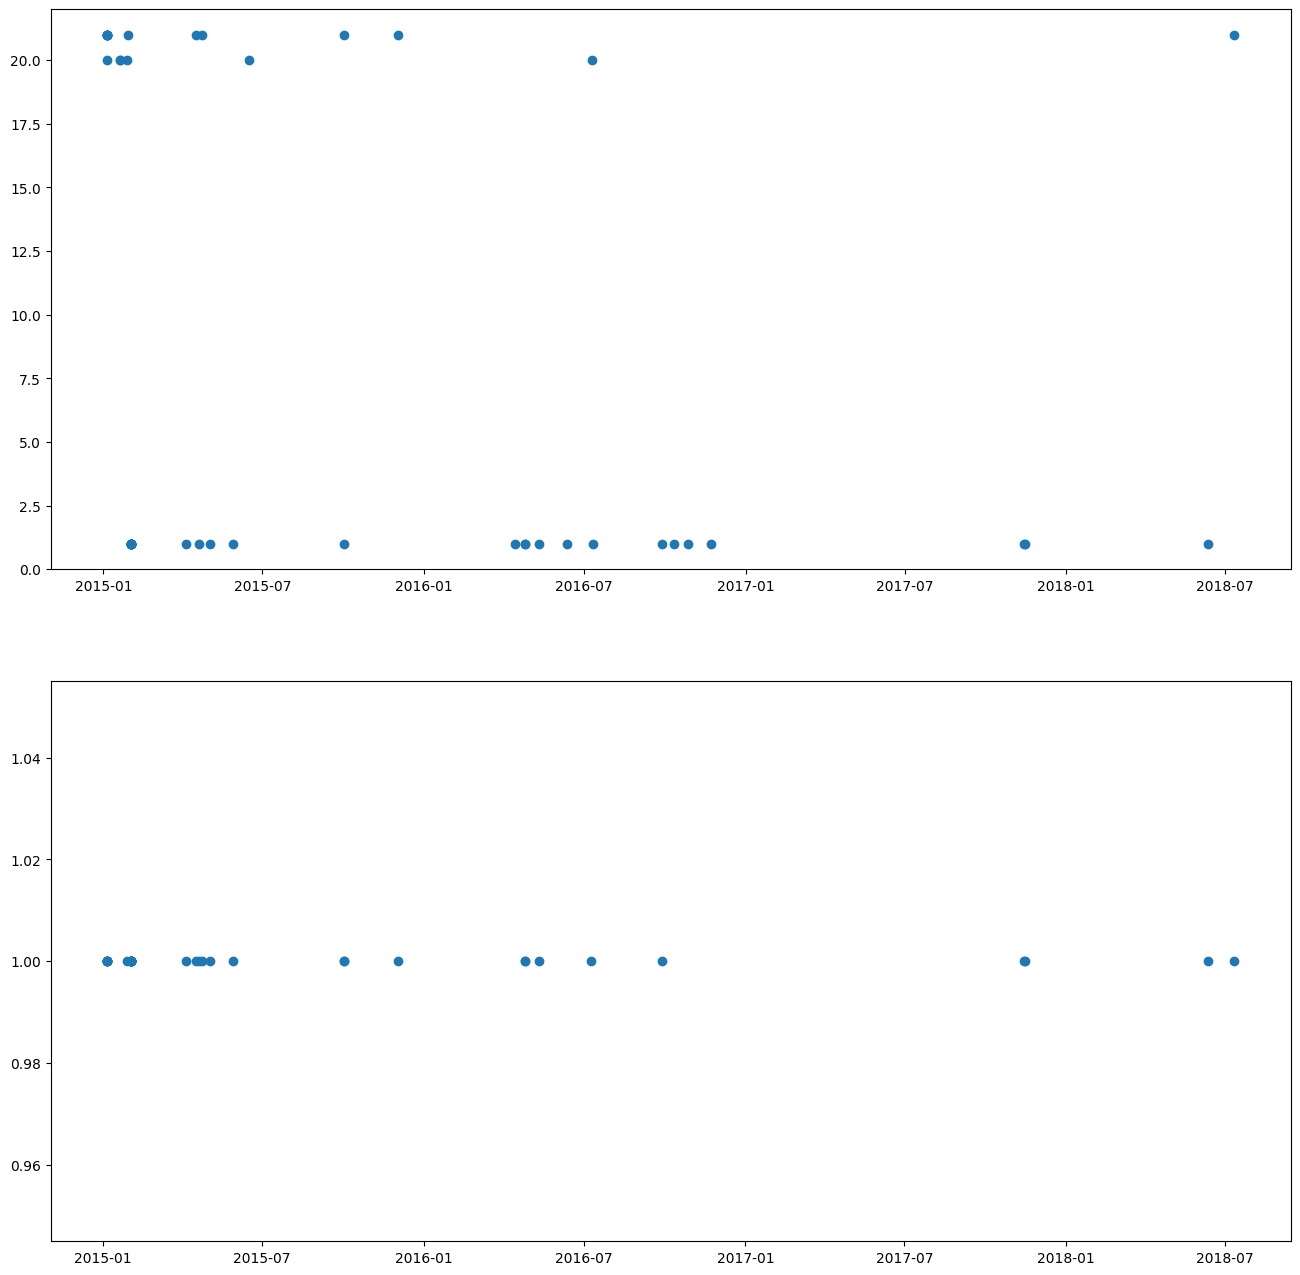

DatetimeIndex(['2015-01-05 11:00:00+00:00', '2015-01-05 12:00:00+00:00',
               '2015-01-05 13:00:00+00:00', '2015-01-05 14:00:00+00:00',
               '2015-01-05 15:00:00+00:00', '2015-01-05 16:00:00+00:00',
               '2015-01-28 12:00:00+00:00', '2015-02-01 06:00:00+00:00',
               '2015-02-01 07:00:00+00:00', '2015-02-01 08:00:00+00:00',
               '2015-02-01 11:00:00+00:00', '2015-02-01 12:00:00+00:00',
               '2015-02-01 13:00:00+00:00', '2015-02-01 14:00:00+00:00',
               '2015-02-01 15:00:00+00:00', '2015-02-01 16:00:00+00:00',
               '2015-02-01 17:00:00+00:00', '2015-02-01 18:00:00+00:00',
               '2015-04-05 01:00:00+00:00', '2015-04-16 07:00:00+00:00',
               '2015-04-20 06:00:00+00:00', '2015-04-23 19:00:00+00:00',
               '2015-05-02 08:00:00+00:00', '2015-05-29 01:00:00+00:00',
               '2015-10-02 06:00:00+00:00', '2015-10-02 09:00:00+00:00',
               '2015-12-02 08:00:00+00:00', '2016-0

In [2]:
import pandas as pd
df = pd.read_csv('energy_dataset.csv')


df["time"] = pd.to_datetime(df["time"],utc=True)
df = df.sort_values("time",ascending=True).set_index("time")

null_count = df.isnull().sum()/df.shape[0]
df = df.dropna(how="all",axis=1)

print(df.shape)
display(df.describe())

df.index.duplicated().any()
repeat = df.T.duplicated()
mod_df = df.loc[:,~repeat]
repeated_columns = df.columns[repeat]
print(f"repeated columns are {repeated_columns}")

times = df.index.to_series().diff().dropna()
if len(times.unique())==1:
    print("time deltas are all the same")
    if times.eq(pd.Timedelta("1 hour")).all():
        print("time delta is 1hour")
else:
    print(times.unique())

bar_na = df.isnull().sum(axis=1)
# bar_na.value_counts().index
print(bar_na.value_counts()[bar_na.value_counts().index>0])
total_load_actual_missing = df["total load actual"].isnull()
print(total_load_actual_missing.sum())

import matplotlib.pyplot as plt

fig,ax = plt.subplots(2,1,figsize=(16,16))
total_load_actual_missing_df = total_load_actual_missing[total_load_actual_missing]
missing_df = bar_na[bar_na>0]
ax[1].scatter(total_load_actual_missing_df.index,total_load_actual_missing_df)
ax[0].scatter(missing_df.index,missing_df)
plt.show()

print(total_load_actual_missing_df.index)
print("common large missing point is ",missing_df[missing_df>1].index.intersection(total_load_actual_missing_df.index))

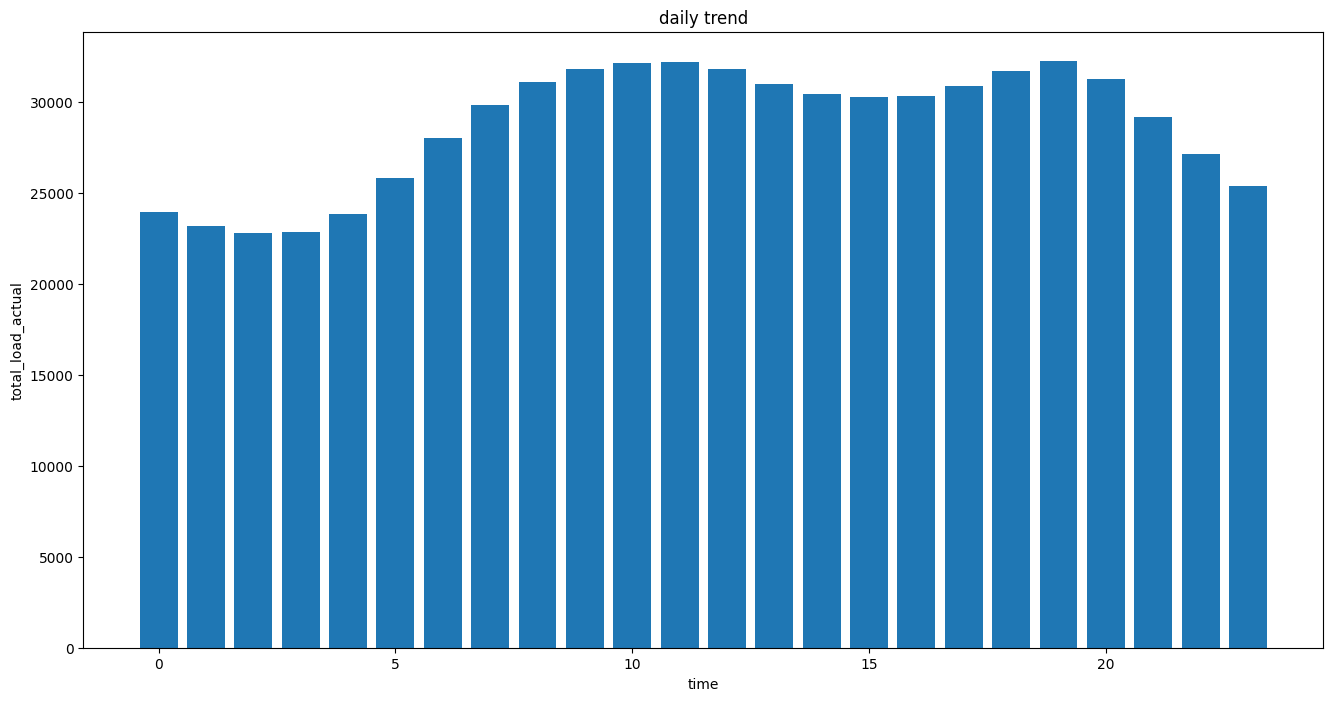

In [3]:
daily_load = df.groupby(df.index.hour)["total load actual"].mean()
fig,ax = plt.subplots(figsize=(16,8))
ax.bar(daily_load.index,daily_load)
ax.set_title("daily trend")
ax.set_xlabel("time")
ax.set_ylabel("total_load_actual")
plt.show()

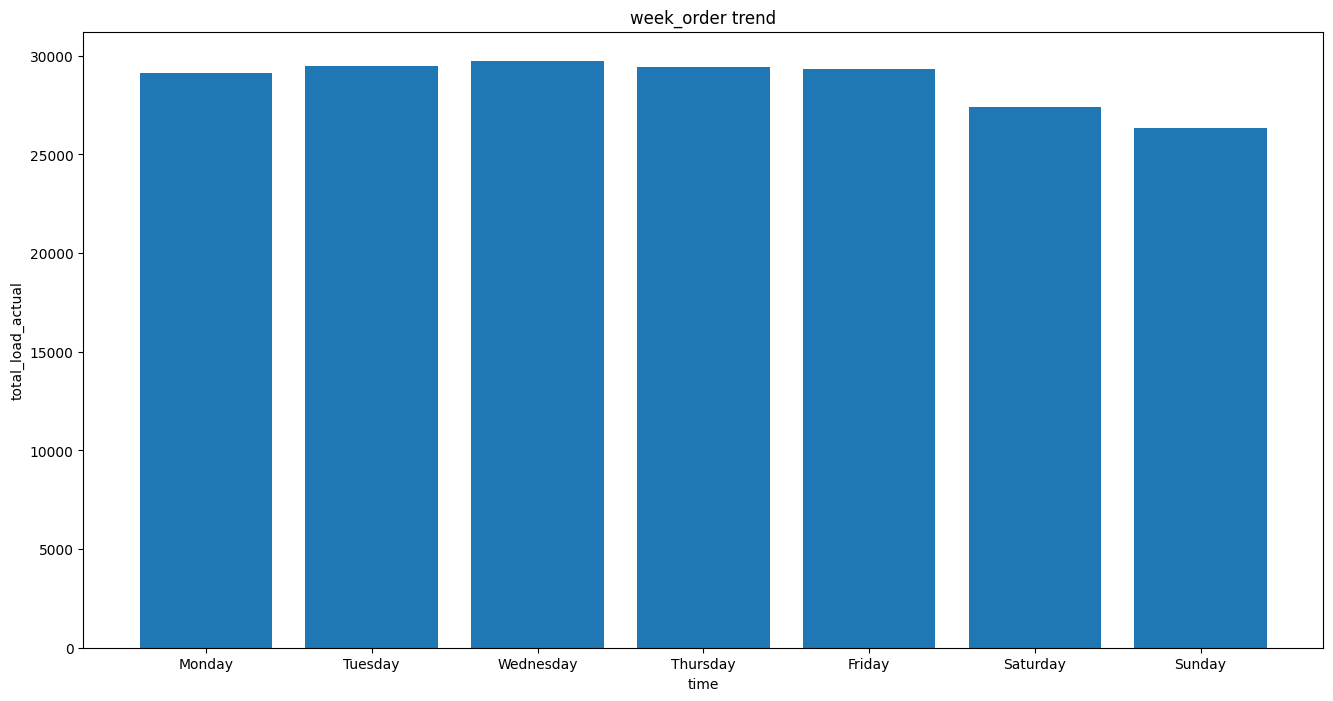

In [4]:
week_order = [
    "Monday", "Tuesday", "Wednesday", "Thursday",
    "Friday", "Saturday", "Sunday"
]
week_load = df.groupby(df.index.day_name())["total load actual"].mean().reindex(week_order)
fig,ax = plt.subplots(figsize=(16,8))
ax.bar(week_load.index,week_load)
ax.set_title("week_order trend")
ax.set_xlabel("time")
ax.set_ylabel("total_load_actual")
plt.show()

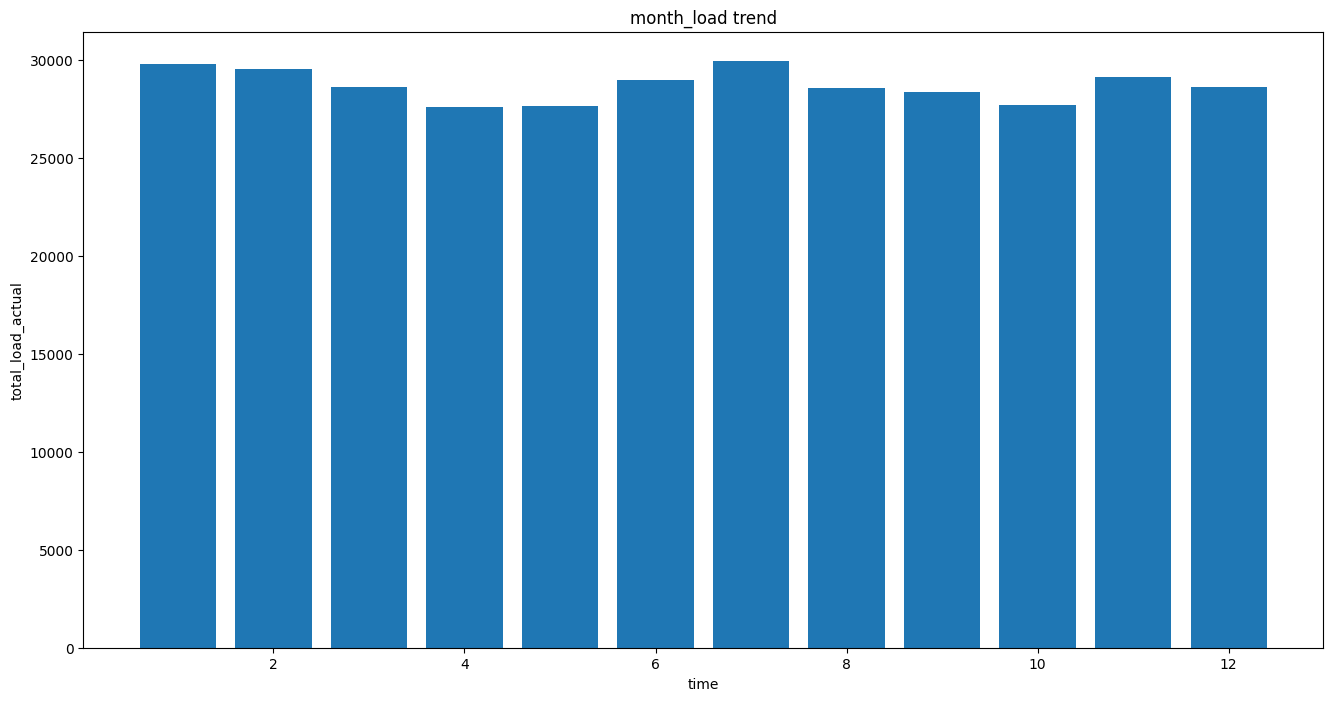

In [5]:
month_load = df.groupby(df.index.month)["total load actual"].mean()
fig,ax = plt.subplots(figsize=(16,8))
ax.bar(month_load.index,month_load)
ax.set_title("month_load trend")
ax.set_xlabel("time")
ax.set_ylabel("total_load_actual")
plt.show()

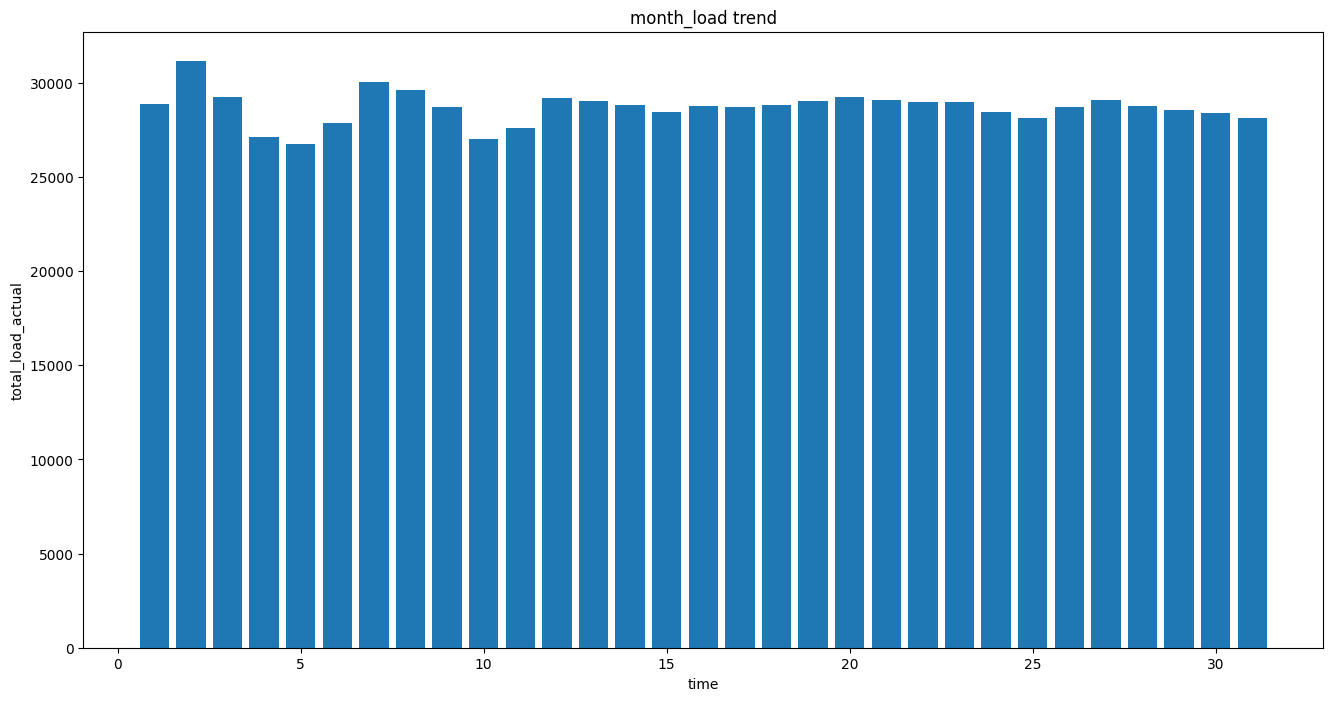

In [6]:
daily_load = df.groupby(df.index.day)["total load actual"].mean()
fig,ax = plt.subplots(figsize=(16,8))
ax.bar(daily_load.index,daily_load)
ax.set_title("month_load trend")
ax.set_xlabel("time")
ax.set_ylabel("total_load_actual")
plt.show()

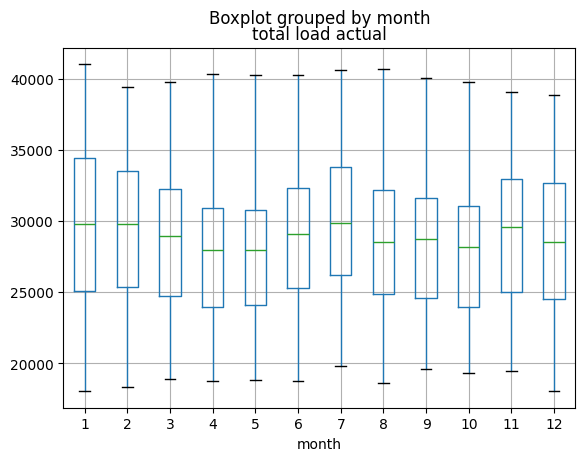

In [7]:
plot_df = df.copy()
plot_df['month'] = plot_df.index.month
ax = plot_df.boxplot(column="total load actual",by="month")


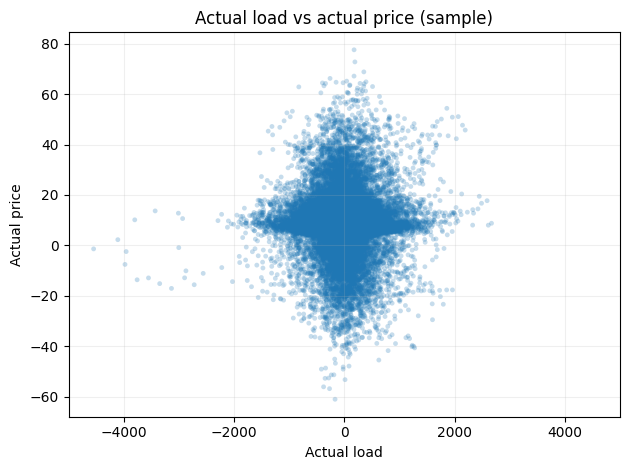

pearson correlation is 0.002983905303113509
spearman correlation is -0.02444217692227252


In [8]:
load_error = df['total load actual'] - df['total load forecast']
price_gap = df["price actual"] - df['price day ahead']
fig, ax = plt.subplots()
ax.scatter(load_error, price_gap,
           s=12, alpha=0.25, color="tab:blue", edgecolors="none")
ax.set(title="Actual load vs actual price (sample)",
       xlabel="Actual load", ylabel="Actual price")
ax.set_xlim(-5000,5000)
ax.grid(alpha=0.2)
fig.tight_layout()

plt.show()
print("pearson correlation is", load_error.corr(price_gap))
print("spearman correlation is", load_error.corr(price_gap,method="spearman"))

/var/folders/vg/fg1y566j11vgl2hx4x_kp6wh0000gn/T/ipykernel_41900/267645377.py:4: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  x = predict_df.groupby("five")["price_gap"].agg(["mean","median","size"])


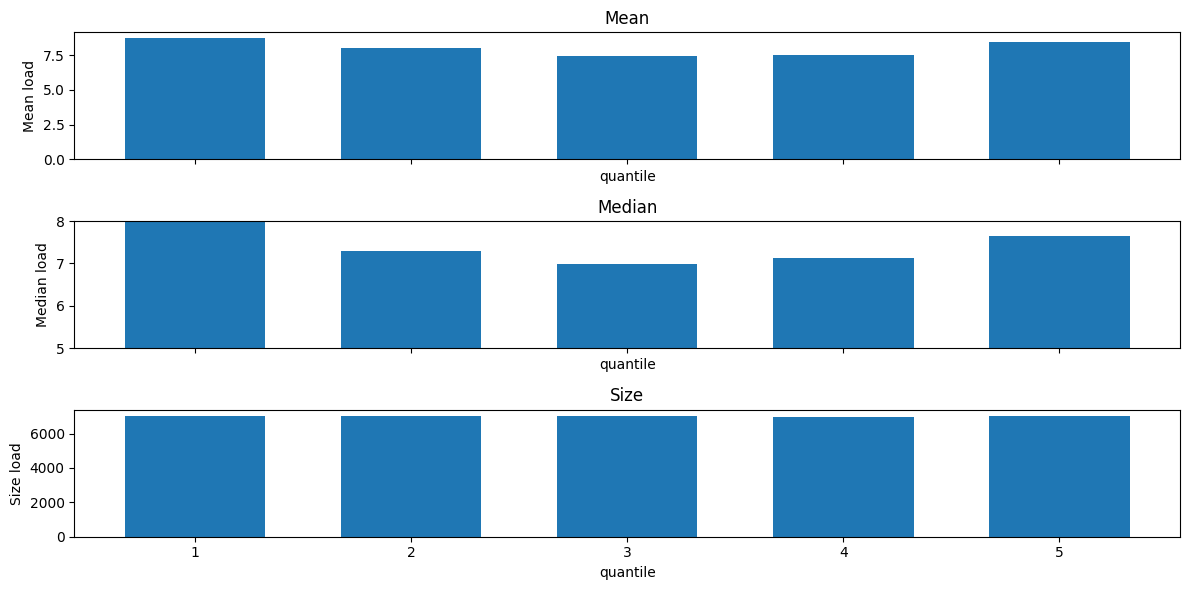

In [9]:
five_parts = pd.qcut(load_error,5)
predict_df = pd.DataFrame({"load_error":load_error,"price_gap":price_gap,"five":five_parts},index=load_error.index)

x = predict_df.groupby("five")["price_gap"].agg(["mean","median","size"])

fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
axes[0].bar([1,2,3,4,5], x.iloc[:,0], color="tab:blue", width=0.65)
axes[1].bar([1,2,3,4,5], x.iloc[:,1], color="tab:blue", width=0.65)
axes[2].bar([1,2,3,4,5], x.iloc[:,2], color="tab:blue", width=0.65)

axes[0].set(title="Mean", xlabel="quantile", ylabel="Mean load")
axes[1].set(title="Median", xlabel="quantile", ylabel="Median load",ylim=(5,8))
axes[2].set(title="Size", xlabel="quantile", ylabel="Size load")

fig.tight_layout()
plt.show()

In [10]:
s = price_gap.abs().nlargest(10)
largest_index = s.index
display(df.loc[largest_index,:])

,generation biomass,generation fossil brown coal/lignite,generation fossil coal-derived gas,generation fossil gas,generation fossil hard coal,generation fossil oil,generation fossil oil shale,generation fossil peat,generation geothermal,generation hydro pumped storage consumption,...,generation solar,generation waste,generation wind offshore,generation wind onshore,forecast solar day ahead,forecast wind onshore day ahead,total load forecast,total load actual,price day ahead,price actual
time,,,,,,,,,,,,,,,,,,,,,
2018-11-03 17:00:00+00:00,266.0,0.0,0.0,2938.0,779.0,168.0,0.0,0.0,0.0,1916.0,...,475.0,283.0,0.0,13522.0,473.0,14725.0,26037.0,26215.0,4.00,81.58
2018-11-03 18:00:00+00:00,282.0,0.0,0.0,2994.0,776.0,176.0,0.0,0.0,0.0,1380.0,...,138.0,278.0,0.0,14346.0,81.0,14708.0,28869.0,29062.0,9.00,81.78
2018-11-03 16:00:00+00:00,265.0,0.0,0.0,2941.0,784.0,164.0,0.0,0.0,0.0,2972.0,...,1147.0,280.0,0.0,14169.0,1243.0,15100.0,25377.0,25732.0,5.00,73.82
2015-01-02 11:00:00+00:00,376.0,0.0,0.0,2606.0,1336.0,197.0,0.0,0.0,0.0,864.0,...,4154.0,177.0,0.0,11230.0,4005.0,10989.0,28894.0,29071.0,7.04,74.19
2015-01-02 14:00:00+00:00,391.0,0.0,0.0,2599.0,1298.0,195.0,0.0,0.0,0.0,1491.0,...,3619.0,188.0,0.0,11961.0,3479.0,11797.0,28231.0,27973.0,5.00,71.24
2015-01-02 09:00:00+00:00,377.0,0.0,0.0,2844.0,1339.0,200.0,0.0,0.0,0.0,938.0,...,2373.0,185.0,0.0,10156.0,2319.0,10379.0,27883.0,27927.0,10.71,75.86
2018-11-03 22:00:00+00:00,263.0,0.0,0.0,2949.0,779.0,193.0,0.0,0.0,0.0,1744.0,...,27.0,276.0,0.0,14872.0,26.0,14664.0,27357.0,27751.0,8.00,72.88
2015-01-02 13:00:00+00:00,383.0,0.0,0.0,2729.0,1354.0,195.0,0.0,0.0,0.0,1047.0,...,3851.0,190.0,0.0,11819.0,3794.0,12078.0,29389.0,29241.0,6.33,71.04
2015-01-02 12:00:00+00:00,373.0,0.0,0.0,2662.0,1341.0,208.0,0.0,0.0,0.0,906.0,...,4074.0,183.0,0.0,11920.0,4120.0,11842.0,29460.0,29439.0,7.00,71.51


## 第五题：用线性回归预测下一小时的实际电价

**任务：** 在小时 t 结束时，利用当时已经知道的信息，预测 t+1 小时的 `price actual`。
练习假设截至 t 的实际价格和负荷都已发布；真实业务需要进一步确认发布时间。
这是每小时更新输入、预测下一小时的滚动一步预测，不是在年初一次预测全年。

第一版只用四个特征，显式写列名，便于检查有没有把目标或未来实际值放进去：

| 特征 | 含义 | 预测时是否已知 |
|---|---|---|
| `price_now` | 当前小时价格 | 是，按本题假设 |
| `price_lag1` | 前一小时价格 | 是 |
| `load_now` | 当前小时实际负荷 | 是，按本题假设 |
| `target_hour` | 下一小时是几点（UTC） | 是，日历信息可提前知道 |

先运行最上面读取 CSV、建立 `df` 的 cell，再从这里依次运行。
这一部分单独创建 `model_df`，保留前面的 EDA 数据。

### 5.1 构造特征 X 和目标 y，检查时间对应关系

`shift(1)` 取上一行，构造历史价格；`shift(-1)` 取下一行，构造预测目标。
**先检查时间连续，再 shift；先构造特征，再按时间切分。**
`target_time` 是目标所属时间，后续按它划分训练、验证和测试集。
缺失目标和必要历史价格的行移除；少量负荷缺失留到训练阶段填补。

In [18]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.dates as mdates

from sklearn.linear_model import LinearRegression
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_absolute_error, mean_squared_error

model_source = df[["price actual", "total load actual"]].copy().sort_index()
assert isinstance(model_source.index, pd.DatetimeIndex), "先把 time 转成时间索引"
assert model_source.index.tz is not None, "时间索引需要时区，本题使用 UTC"
model_source.index = model_source.index.tz_convert("UTC")
assert model_source.index.is_unique, "存在重复时间，需要先检查"
gaps = model_source.index.to_series().diff().dropna()
assert len(gaps) > 0 and gaps.eq(pd.Timedelta(hours=1)).all(), "时间必须按小时连续"

model_df = pd.DataFrame(index=model_source.index)
model_df["price_now"] = model_source["price actual"]
model_df["price_lag1"] = model_source["price actual"].shift(1)
model_df["load_now"] = model_source["total load actual"]
model_df["target_time"] = model_df.index + pd.Timedelta(hours=1)
model_df["target_hour"] = model_df["target_time"].dt.hour
model_df["target"] = model_source["price actual"].shift(-1)

model_df = model_df.dropna(subset=["price_now", "price_lag1", "target"])
feature_columns = ["price_now", "price_lag1", "load_now", "target_hour"]

print("Samples:", len(model_df))
print("Missing feature values:")
display(model_df[feature_columns].isna().sum().to_frame("missing_count"))
display(model_df[["target_time"] + feature_columns + ["target"]].head(6))

Samples: 35062
Missing feature values:


,missing_count
price_now,0
price_lag1,0
load_now,36
target_hour,0


,target_time,price_now,price_lag1,load_now,target_hour,target
time,,,,,,
2015-01-01 00:00:00+00:00,2015-01-01 01:00:00+00:00,64.92,65.41,24382.0,1,64.48
2015-01-01 01:00:00+00:00,2015-01-01 02:00:00+00:00,64.48,64.92,22734.0,2,59.32
2015-01-01 02:00:00+00:00,2015-01-01 03:00:00+00:00,59.32,64.48,21286.0,3,56.04
2015-01-01 03:00:00+00:00,2015-01-01 04:00:00+00:00,56.04,59.32,20264.0,4,53.63
2015-01-01 04:00:00+00:00,2015-01-01 05:00:00+00:00,53.63,56.04,19905.0,5,51.73
2015-01-01 05:00:00+00:00,2015-01-01 06:00:00+00:00,51.73,53.63,20010.0,6,51.43


### 5.2 按目标时间切分，X 保持 DataFrame，y 使用 Series

- 2015—2016 年：训练。
- 2017 年：验证。
- 2018 年：最终测试。

你原来的布尔条件报错，是因为 `&` 两边的比较表达式需要分别加括号：
`(time >= start) & (time < end)`。
按 `target_time` 分组也避免把下一年首个目标误放进上一年的训练集。
每行特征的 index 仍然是信息时刻 t，比 `target_time` 早一小时。

In [19]:
train_mask = (
    (model_df["target_time"] >= "2015-01-01")
    & (model_df["target_time"] < "2017-01-01")
)
val_mask = (
    (model_df["target_time"] >= "2017-01-01")
    & (model_df["target_time"] < "2018-01-01")
)
test_mask = (
    (model_df["target_time"] >= "2018-01-01")
    & (model_df["target_time"] < "2019-01-01")
)

train_df = model_df.loc[train_mask].copy()
val_df = model_df.loc[val_mask].copy()
test_df = model_df.loc[test_mask].copy()

X_train = train_df[feature_columns]
y_train = train_df["target"]
X_val = val_df[feature_columns]
y_val = val_df["target"]
X_test = test_df[feature_columns]
y_test = test_df["target"]

split_summary = pd.DataFrame([
    {"split": name, "samples": len(part),
     "first_target": part["target_time"].min(),
     "last_target": part["target_time"].max()}
    for name, part in [("train", train_df), ("validation", val_df), ("test", test_df)]
]).set_index("split")
display(split_summary)
print("X_train:", type(X_train).__name__, X_train.shape)
print("y_train:", type(y_train).__name__, y_train.shape)

,samples,first_target,last_target
split,,,
train,17543,2015-01-01 01:00:00+00:00,2016-12-31 23:00:00+00:00
validation,8760,2017-01-01 00:00:00+00:00,2017-12-31 23:00:00+00:00
test,8759,2018-01-01 00:00:00+00:00,2018-12-31 22:00:00+00:00


X_train: DataFrame (17543, 4)
y_train: Series (17543,)


### 5.3 训练线性回归，在验证集上和基准比较

基准预测：下一小时价格等于当前小时价格，即 `prediction = price_now`。

`LinearRegression` 不能直接接收缺失值。这里用训练集各列的中位数填补：
`make_pipeline(SimpleImputer(...), LinearRegression())` 把填补和模型接在一起。

- `model.fit(X_train, y_train)`：先从训练集学习填补值，再拟合回归系数。
- `model.predict(X_val)`：沿用训练时的填补值，预测验证集，不会用验证集重新计算中位数。

MAE 是平均绝对误差；RMSE 对较大的误差更敏感。两者都越小越好，单位与价格相同。

In [20]:
def regression_metrics(y_true, y_pred):
    return {
        "MAE": mean_absolute_error(y_true, y_pred),
        "RMSE": np.sqrt(mean_squared_error(y_true, y_pred)),
    }

# Pipeline 仍然使用相同的 fit / predict 接口
model = make_pipeline(
    SimpleImputer(strategy="median"),
    LinearRegression(),
)
model.fit(X_train, y_train)

val_baseline_pred = X_val["price_now"].to_numpy()
val_linear_pred = model.predict(X_val)

val_results = pd.DataFrame({
    "Current-price baseline": regression_metrics(y_val, val_baseline_pred),
    "Linear regression": regression_metrics(y_val, val_linear_pred),
}).T
display(val_results.round(4))

val_mae_improvement = (
    1 - val_results.loc["Linear regression", "MAE"]
    / val_results.loc["Current-price baseline", "MAE"]
) * 100
print(f"Validation MAE improvement vs baseline: {val_mae_improvement:.2f}%")
print("Positive means lower MAE; negative means worse than the baseline.")

model.named_steps

/Library/Frameworks/Python.framework/Versions/3.9/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.9/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.9/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


,MAE,RMSE
Current-price baseline,2.3785,3.5136
Linear regression,1.9573,2.9178


Validation MAE improvement vs baseline: 17.71%
Positive means lower MAE; negative means worse than the baseline.


{'simpleimputer': SimpleImputer(strategy='median'),
 'linearregression': LinearRegression()}

### 5.4 看线性模型到底学到了什么

形式是：预测价格 = 截距 + 每个特征 × 对应系数。
`named_steps["linearregression"]` 取出 Pipeline 中的线性回归部分。
`coef_` 是系数，`intercept_` 是截距；末尾下划线通常表示拟合后得到的属性。

系数描述的是其他输入保持不变时的拟合关系；不直接代表因果作用。
特征单位不同，而且价格历史之间可能相关，因此不要仅按系数绝对值排名“重要性”。
这里用数字表示小时，是便于入门的简化；之后可以探索周期编码或类别编码。

In [13]:
linear_step = model.named_steps["linearregression"]
coefficient_table = pd.DataFrame({
    "feature": feature_columns,
    "coefficient": linear_step.coef_,
}).set_index("feature")

display(coefficient_table.round(6))
print("Intercept:", round(linear_step.intercept_, 6))

,coefficient
feature,
price_now,1.473084
price_lag1,-0.511190
load_now,-0.000054
target_hour,-0.042336


Intercept: 4.090456


### 5.5 固定方案，用训练集和验证集合并重训，再评估测试集

这一版固定使用以上四个特征和普通线性回归。验证结果用于判断它相对基准的表现。
之后若要改变特征或模型，先在验证阶段比较；测试结果用于报告最终表现。

合并训练集和验证集后，重新创建 `final_model`，填补值和回归系数都只从这两部分学习。
测试集不参与拟合。两种方法在相同测试样本上比较。

In [14]:
train_val_df = pd.concat([train_df, val_df]).sort_index()

final_model = make_pipeline(
    SimpleImputer(strategy="median"),
    LinearRegression(),
)
final_model.fit(train_val_df[feature_columns], train_val_df["target"])

test_baseline_pred = X_test["price_now"].to_numpy()
test_linear_pred = final_model.predict(X_test)

test_results = pd.DataFrame({
    "Current-price baseline": regression_metrics(y_test, test_baseline_pred),
    "Linear regression": regression_metrics(y_test, test_linear_pred),
}).T
display(test_results.round(4))

test_mae_improvement = (
    1 - test_results.loc["Linear regression", "MAE"]
    / test_results.loc["Current-price baseline", "MAE"]
) * 100
print(f"Test MAE improvement vs baseline: {test_mae_improvement:.2f}%")

# 用目标时刻做索引，画图时真实值和预测值对应同一个小时
test_predictions = pd.DataFrame({
    "Actual": y_test.to_numpy(),
    "Baseline": test_baseline_pred,
    "Linear regression": test_linear_pred,
}, index=pd.DatetimeIndex(test_df["target_time"], name="target_time"))
display(test_predictions.head())

/Library/Frameworks/Python.framework/Versions/3.9/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: divide by zero encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.9/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: overflow encountered in matmul
  return X @ coef_ + self.intercept_
/Library/Frameworks/Python.framework/Versions/3.9/lib/python3.9/site-packages/sklearn/linear_model/_base.py:279: RuntimeWarning: invalid value encountered in matmul
  return X @ coef_ + self.intercept_


,MAE,RMSE
Current-price baseline,2.2587,3.3421
Linear regression,1.9153,2.8116


Test MAE improvement vs baseline: 15.20%


,Actual,Baseline,Linear regression
target_time,,,
2018-01-01 00:00:00+00:00,19.02,20.76,21.260601
2018-01-01 01:00:00+00:00,17.90,19.02,20.334448
2018-01-01 02:00:00+00:00,20.88,17.90,19.601444
2018-01-01 03:00:00+00:00,18.83,20.88,24.592234
2018-01-01 04:00:00+00:00,15.80,18.83,20.003084


### 5.6 画连续一周的结果，再检查哪些小时误差较大

这里画 2018 年 1 月 1—7 日（UTC）。三条线分别是真实价格、基准和线性回归。
单周曲线用来检查局部形态，整体效果仍看完整测试集的 MAE / RMSE。
最后的分组表按目标小时汇总线性模型的绝对误差，用来寻找后续研究方向。

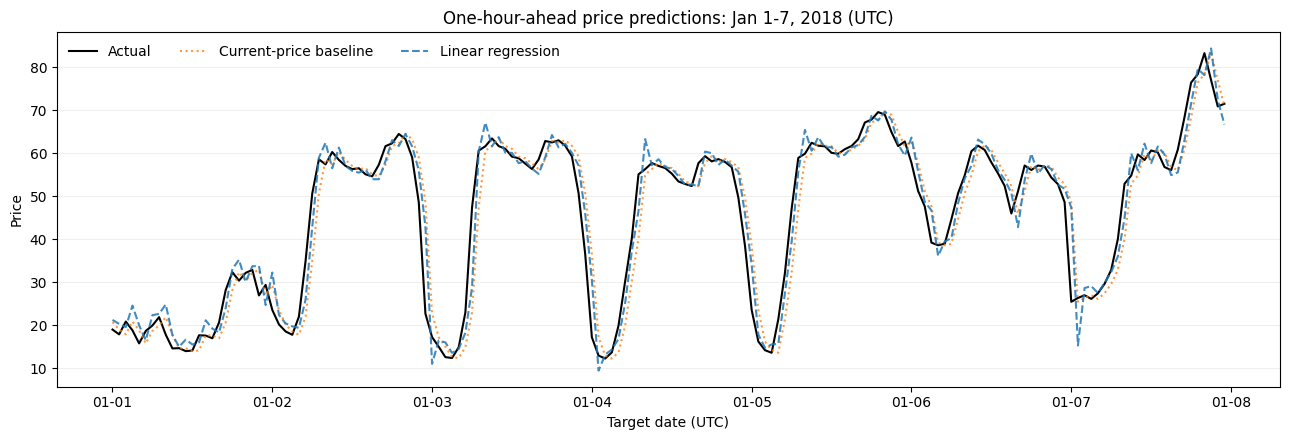

,MAE,samples
target_hour_UTC,,
17,3.2331,365
6,2.8230,365
0,2.6526,365
5,2.5890,365
22,2.5361,365
23,2.4335,364


In [15]:
prediction_week = test_predictions.loc["2018-01-01":"2018-01-07"]

fig, ax = plt.subplots(figsize=(13, 4.5))
ax.plot(prediction_week.index, prediction_week["Actual"],
        color="black", linewidth=1.5, label="Actual")
ax.plot(prediction_week.index, prediction_week["Baseline"],
        color="tab:orange", linestyle=":", alpha=0.8, label="Current-price baseline")
ax.plot(prediction_week.index, prediction_week["Linear regression"],
        color="tab:blue", linestyle="--", alpha=0.85, label="Linear regression")
ax.xaxis.set_major_locator(mdates.DayLocator(interval=1))
ax.xaxis.set_major_formatter(mdates.DateFormatter("%m-%d"))
ax.set(title="One-hour-ahead price predictions: Jan 1-7, 2018 (UTC)",
       xlabel="Target date (UTC)", ylabel="Price")
ax.legend(ncol=3, frameon=False)
ax.grid(axis="y", alpha=0.2)
fig.tight_layout()
plt.show()

test_abs_error = (
    test_predictions["Actual"] - test_predictions["Linear regression"]
).abs()
hourly_error = (
    test_abs_error.groupby(test_abs_error.index.hour)
    .agg(["mean", "count"])
    .rename(columns={"mean": "MAE", "count": "samples"})
)
hourly_error.index.name = "target_hour_UTC"
display(hourly_error.sort_values("MAE", ascending=False).head(6).round(4))

### 看完结果后，用自己的话回答

1. 验证集和测试集上，线性回归是否都超过当前价格基准？MAE 和 RMSE 的结论一致吗？
2. 哪些目标小时的误差较大？一周曲线中，模型对突然变化的价格表现如何？
3. 为什么可以把目标小时作为特征，却不能使用下一小时的实际负荷？

核心接口只有 `model.fit(X_train, y_train)` 和 `model.predict(X_val)`。
前后的代码是在保证样本时间对应正确、缺失处理只学习训练数据，并且评估有可比较的基准。